# Exploratory data analysis: dataset basics and descriptive statistics

Inputs: `data/interim/client.parquet`, `data/interim/invoice.parquet` (raw values, from `python run.py interim`) and
`data/interim/invoice_clean.parquet` (for the derived `cons` and `cons_pm`).

* **Descriptive statistics** cover every raw variable on **all** rows. They do not use the label.
* **Anything split by class** (fraud vs non-fraud) uses **training clients only** (`data/splits/train_ids.csv`),
  so the held-out test set never shapes our modelling choices.

Outputs: `results/tables/basics.csv`, `results/tables/descriptive.csv`, and four figures in `results/figures/`.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.viz import style

style.apply()
TABLES, FIGURES = Path("results/tables"), Path("results/figures")
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

clients = pd.read_parquet("data/interim/client.parquet")
raw = pd.read_parquet("data/interim/invoice.parquet")
clean = pd.read_parquet(
    "data/interim/invoice_clean.parquet",
    columns=["client_id", "invoice_date", "counter_type", "cons", "cons_pm", "flag_partial_year"],
)
train_ids = set(pd.read_csv("data/splits/train_ids.csv", dtype={"client_id": "string"}).client_id)
print(
    f"{len(clients):,} clients, {len(raw):,} raw invoices, {len(clean):,} clean invoices, {len(train_ids):,} training clients"
)

135,493 clients, 4,476,749 raw invoices, 4,476,749 clean invoices, 108,394 training clients


## 1. Dataset basics

In [2]:
per_client = clean.groupby("client_id").size()
types = clean.groupby("client_id")["counter_type"].agg(lambda s: frozenset(s.unique()))
q1, med, q3 = per_client.quantile([0.25, 0.5, 0.75])
basics = pd.DataFrame(
    [
        ("clients", len(clients)),
        ("fraud clients", int(clients.target.sum())),
        ("fraud rate (%)", round(100 * clients.target.mean(), 2)),
        ("invoices (after cleaning)", len(clean)),
        ("invoices per client: median", med),
        ("invoices per client: Q1", q1),
        ("invoices per client: Q3", q3),
        ("invoices per client: IQR", q3 - q1),
        ("clients with ELEC only (%)", round(100 * (types == frozenset({"ELEC"})).mean(), 2)),
        ("clients with GAZ only (%)", round(100 * (types == frozenset({"GAZ"})).mean(), 2)),
        (
            "clients with both ELEC and GAZ (%)",
            round(100 * (types == frozenset({"ELEC", "GAZ"})).mean(), 2),
        ),
        (
            "invoice date range",
            f"{clean.invoice_date.min():%Y-%m-%d} to {clean.invoice_date.max():%Y-%m-%d}",
        ),
    ],
    columns=["statistic", "value"],
)
basics.to_csv(TABLES / "basics.csv", index=False)
basics

,statistic,value
0,clients,135493
1,fraud clients,7566
2,fraud rate (%),5.58
3,invoices (after cleaning),4476749
4,invoices per client: median,30.0
5,invoices per client: Q1,10.0
6,invoices per client: Q3,50.0
7,invoices per client: IQR,40.0
8,clients with ELEC only (%),54.2
9,clients with GAZ only (%),0.5


## 2. Descriptive statistics for every raw variable

Measures (`consommation_level_*`, indexes, `months_number`, `counter_coefficient`) get the full set of statistics.
`mad` is the unscaled median absolute deviation, median(|x − median|); multiply by 1.4826 to get a robust σ.
`kurtosis` is excess kurtosis (normal = 0).
Codes (`district`, `region`, `client_catg`, `tarif_type`, `counter_statue`, `counter_code`, `reading_remarque`,
`counter_type`) are categories. Averaging them is meaningless, so we report `n_unique` and the top value and its share.
Dates are summarised as decimal years. Identifiers get only counts.
The derived `cons` and `cons_pm` from the clean file are included and marked `derived`.

In [3]:
KIND = {
    "district": "categorical",
    "client_catg": "categorical",
    "region": "categorical",
    "creation_date": "date",
    "target": "binary",
    "client_id": "identifier",
    "invoice_date": "date",
    "tarif_type": "categorical",
    "counter_number": "identifier",
    "counter_statue": "categorical",
    "counter_code": "categorical",
    "reading_remarque": "categorical",
    "counter_coefficient": "numeric",
    "old_index": "numeric",
    "new_index": "numeric",
    "months_number": "numeric",
    "counter_type": "categorical",
    **{f"consommation_level_{i}": "numeric" for i in range(1, 5)},
}


def decimal_year(d):
    return d.dt.year + (d.dt.dayofyear - 1) / 365.25


def describe(table, name, s, kind):
    row = {
        "table": table,
        "variable": name,
        "kind": kind,
        "dtype": str(s.dtype),
        "n": len(s),
        "pct_missing": round(100 * s.isna().mean(), 4),
        "n_unique": s.nunique(),
    }
    if kind in ("categorical", "identifier", "binary"):
        top = s.astype("string").value_counts()
        row.update(top_value=top.index[0], top_share=round(top.iloc[0] / s.notna().sum(), 4))
    if kind in ("numeric", "date", "binary", "derived"):
        x = (decimal_year(s) if kind == "date" else s.astype("float64")).dropna()
        q = x.quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy()
        row.update(
            min=q[0],
            q1=q[1],
            median=q[2],
            q3=q[3],
            max=q[4],
            iqr=q[3] - q[1],
            mean=x.mean(),
            std=x.std(),
            mad=(x - q[2]).abs().median(),
            skew=x.skew(),
            kurtosis=x.kurt(),
        )
    return row


rows = [describe("client", c, clients[c], KIND[c]) for c in clients.columns]
rows += [describe("invoice", c, raw[c], KIND[c]) for c in raw.columns]
rows += [describe("invoice (derived)", c, clean[c], "derived") for c in ("cons", "cons_pm")]
descriptive = pd.DataFrame(rows)
descriptive.to_csv(TABLES / "descriptive.csv", index=False)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
descriptive

,table,variable,kind,dtype,n,pct_missing,n_unique,top_value,top_share,min,q1,median,q3,max,iqr,mean,std,mad,skew,kurtosis
0,client,district,categorical,string,135493,0.000,4,62,0.298,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,client,client_id,identifier,string,135493,0.000,135493,train_Client_0,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,client,client_catg,categorical,string,135493,0.000,3,11,0.971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,client,region,categorical,string,135493,0.000,25,101,0.249,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,client,creation_date,date,datetime64[ns],135493,0.000,8088,NaN,NaN,"1,977.096","1,994.030","2,005.715","2,012.257","2,019.690",18.227,"2,002.750",11.541,8.156,-0.545,-0.841
5,client,target,binary,int8,135493,0.000,2,0,0.944,0.000,0.000,0.000,0.000,1.000,0.000,0.056,0.230,0.000,3.869,12.968
6,invoice,client_id,identifier,string,4476749,0.000,135493,train_Client_116878,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,invoice,invoice_date,date,datetime64[ns],4476749,0.000,8275,NaN,NaN,"1,977.435","2,010.049","2,013.520","2,016.674","2,019.931",6.624,"2,013.210",4.094,3.309,-0.579,1.313
8,invoice,tarif_type,categorical,int64,4476749,0.000,17,11,0.599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,invoice,counter_number,identifier,string,4476749,0.000,207431,0000,0.009,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Histogram of every raw variable

Measures are very right-skewed (see the skew and kurtosis columns), so they are shown on a log10(x + 1) axis.
Codes are shown as the share of rows for their 8 most common values. For the identifiers we plot invoices per client;
`counter_number` is an identifier with no meaningful distribution, so it is left out.

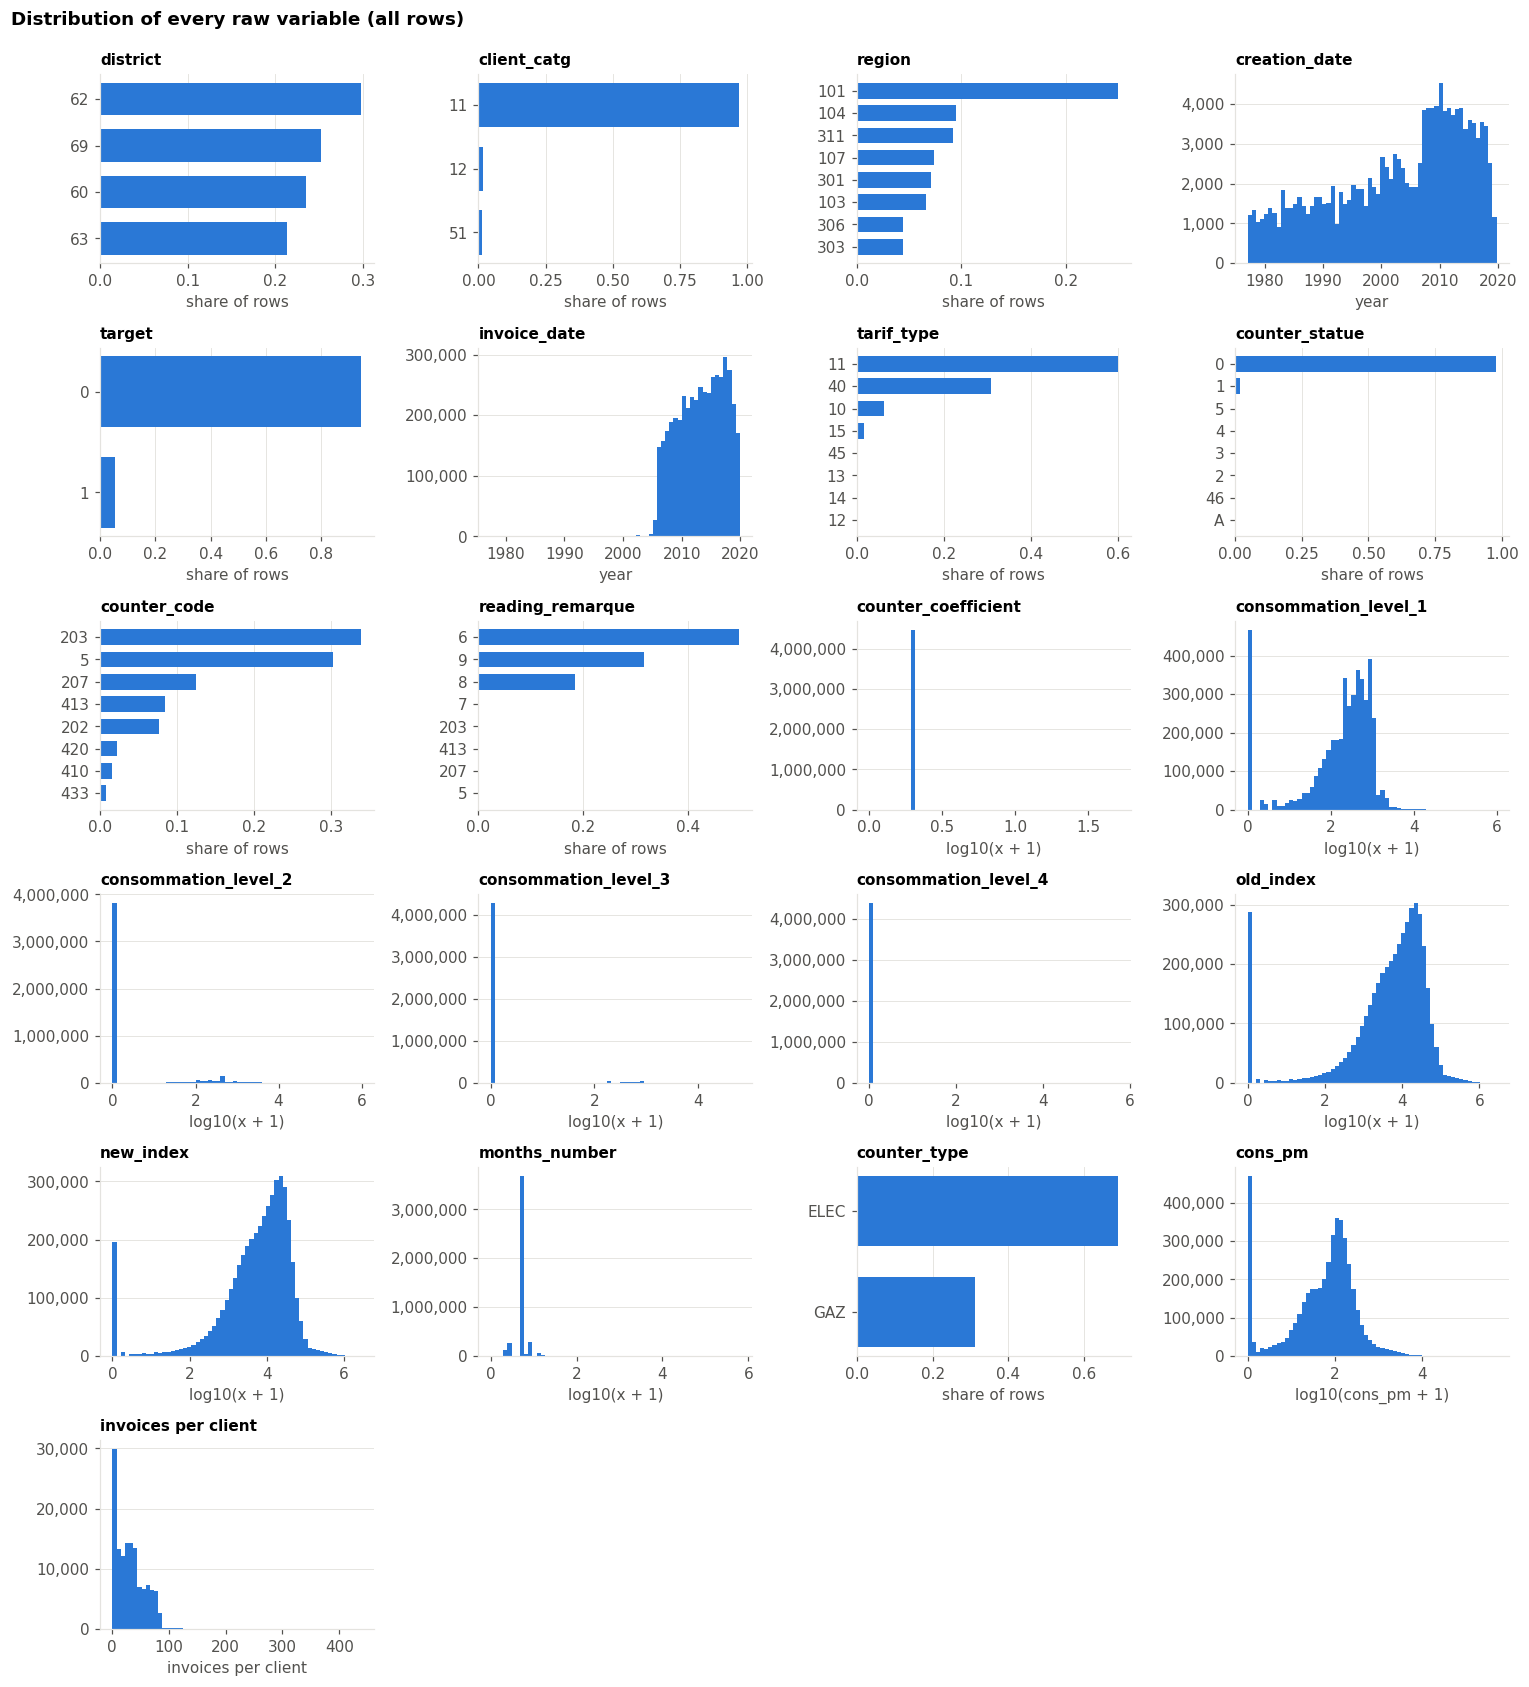

In [4]:
panels = (
    [("client", c) for c in clients.columns if c != "client_id"]
    + [("invoice", c) for c in raw.columns if c not in ("client_id", "counter_number")]
    + [("derived", "cons_pm"), ("client", "invoices per client")]
)
ncols = 4
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.6 * nrows))
for ax, (table, name) in zip(axes.flat, panels):
    if name == "invoices per client":
        ax.hist(per_client, bins=60, color=style.SINGLE)
        ax.set_xlabel("invoices per client")
    elif name == "cons_pm":
        ax.hist(np.log10(clean.cons_pm.dropna().clip(lower=0) + 1), bins=60, color=style.SINGLE)
        ax.set_xlabel("log10(cons_pm + 1)")
    else:
        s = (clients if table == "client" else raw)[name]
        kind = KIND[name]
        if kind in ("categorical", "binary"):
            share = s.astype("string").value_counts(normalize=True).head(8)[::-1]
            ax.barh(share.index, share.values, color=style.SINGLE, height=0.7)
            ax.set_xlabel("share of rows")
            ax.grid(axis="x")
            ax.grid(axis="y", visible=False)
        elif kind == "date":
            ax.hist(decimal_year(s), bins=60, color=style.SINGLE)
            ax.set_xlabel("year")
        else:
            ax.hist(np.log10(s.astype("float64").clip(lower=0) + 1), bins=60, color=style.SINGLE)
            ax.set_xlabel("log10(x + 1)")
    ax.set_title(name, fontsize=10)
    if not ax.get_xlabel().startswith("share"):
        ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
for ax in axes.flat[len(panels) :]:
    ax.remove()
fig.suptitle("Distribution of every raw variable (all rows)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(FIGURES / "eda_raw_histograms.png")
plt.show()

## 3. Monthly consumption by class (training clients)

There is one value per client, because the client is what we score: the **median `cons_pm`** over that client's invoices.
14 clients have no usable `cons_pm` (every invoice has an impossible period) and are left out.
The bins are equal-width on a log scale. Each bar shows the **share of that class's clients** in the bin, not a density,
because a density on log-spaced bins would inflate the narrow bins on the left. Clients whose median is exactly 0
cannot be drawn on a log axis, so their share is given in the legend.

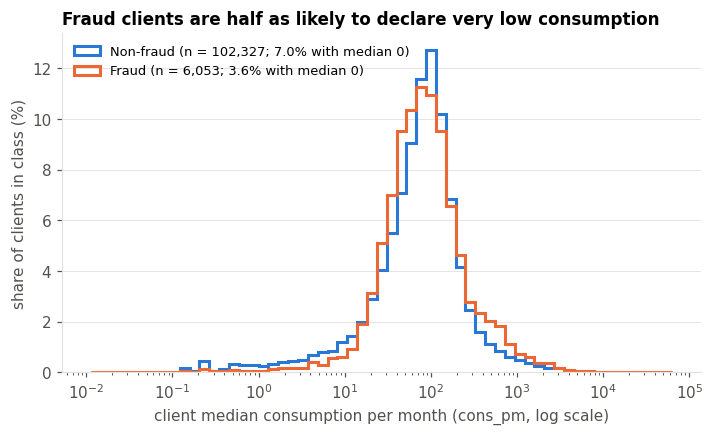

,count,mean,std,min,25%,50%,75%,max,share_below_10
target,,,,,,,,,
0,"102,327.000",138.539,516.087,0.000,31.375,74.250,127.375,"63,687.500",0.138
1,"6,053.000",165.495,401.639,0.000,40.375,77.000,143.500,"12,665.000",0.065


In [5]:
train_clients = clients[clients.client_id.isin(train_ids)].set_index("client_id")
med_pm = clean[clean.client_id.isin(train_ids)].groupby("client_id").cons_pm.median()
df = train_clients[["target"]].join(med_pm.rename("cons_pm_median"), how="inner").dropna()

positive = df.cons_pm_median[df.cons_pm_median > 0]
bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60)
fig, ax = plt.subplots(figsize=(7.5, 4))
for t in (0, 1):
    x = df.loc[df.target == t, "cons_pm_median"]
    ax.hist(
        x[x > 0],
        bins=bins,
        weights=np.full((x > 0).sum(), 100 / len(x)),
        histtype="step",
        lw=2,
        color=style.CLASS_COLORS[t],
        label=f"{style.CLASS_LABELS[t]} (n = {len(x):,}; {(x == 0).mean():.1%} with median 0)",
    )
ax.set_xscale("log")
ax.set_xlabel("client median consumption per month (cons_pm, log scale)")
ax.set_ylabel("share of clients in class (%)")
ax.set_title("Fraud clients are half as likely to declare very low consumption")
ax.legend(loc="upper left", fontsize=8.5)
fig.savefig(FIGURES / "eda_cons_pm_by_class.png")
plt.show()

summary = df.groupby("target").cons_pm_median.describe()
summary["share_below_10"] = df.groupby("target").cons_pm_median.apply(lambda x: (x < 10).mean())
summary

## 4. Invoices per year

Before 2005 there are very few invoices, so those years are grouped together.
2018 dips below 2017 (September 2018 has under 40% of a normal month), so year-on-year features should compare
per-month rates, not raw annual totals. 2019 is lighter because the final year is incomplete: September to December run at 26–40% of the 2018 median monthly volume
(`flag_partial_year` in the clean file; see `results/tables/data_quality.csv`).

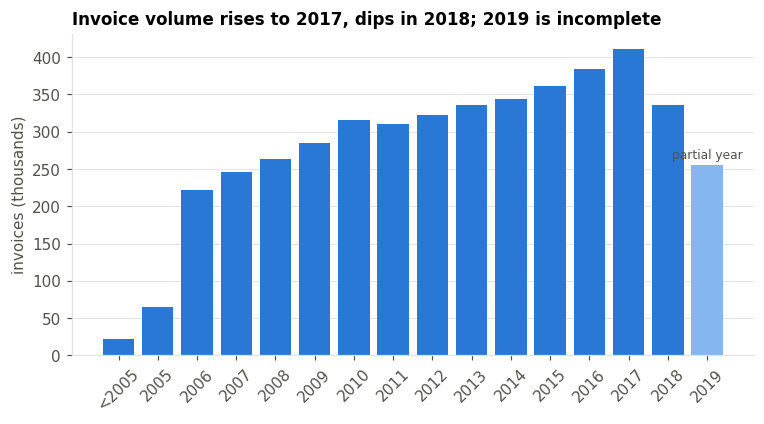

invoice_date,<2005,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
invoices,22112,64663,221771,246189,263216,284375,316229,310402,322116,335944,343374,360759,383654,410932,335650,255363


In [6]:
year = clean.invoice_date.dt.year
by_year = year.where(year >= 2005, 2004).value_counts().sort_index()
labels = ["<2005" if y == 2004 else str(y) for y in by_year.index]
colors = [style.MUTED if y == year.max() else style.SINGLE for y in by_year.index]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(labels, by_year.values / 1e3, color=colors, width=0.8)
ax.annotate(
    "partial year",
    (len(labels) - 1, by_year.iloc[-1] / 1e3),
    xytext=(0, 4),
    textcoords="offset points",
    ha="center",
    fontsize=8,
    color=style.TEXT_SECONDARY,
)
ax.set_ylabel("invoices (thousands)")
ax.set_title("Invoice volume rises to 2017, dips in 2018; 2019 is incomplete")
ax.tick_params(axis="x", rotation=45)
fig.savefig(FIGURES / "eda_invoices_per_year.png")
plt.show()
by_year.rename(index={2004: "<2005"}).to_frame("invoices").T

## 5. Fraud rate by client category (training clients)

The error bars are 95% Wilson intervals. The dashed line is the overall training fraud rate.

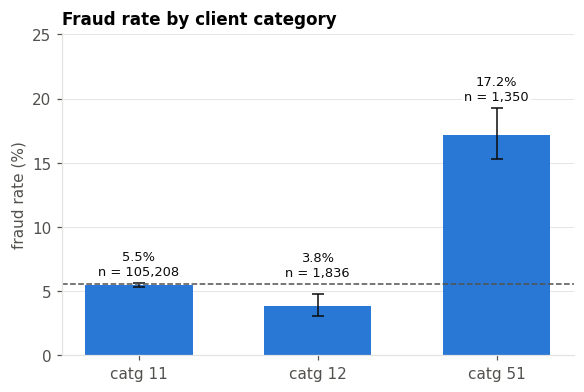

,sum,count,rate,lo,hi
client_catg,,,,,
11,5751,105208,0.055,0.053,0.056
12,70,1836,0.038,0.030,0.048
51,232,1350,0.172,0.153,0.193


In [7]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


g = train_clients.groupby("client_catg").target.agg(["sum", "count"])
g["rate"] = g["sum"] / g["count"]
g["lo"], g["hi"] = wilson(g["sum"], g["count"])
fig, ax = plt.subplots(figsize=(6, 3.8))
x = np.arange(len(g))
ax.bar(x, 100 * g.rate, color=style.SINGLE, width=0.6)
ax.errorbar(
    x,
    100 * g.rate,
    yerr=[100 * (g.rate - g.lo), 100 * (g.hi - g.rate)],
    fmt="none",
    ecolor=style.TEXT,
    elinewidth=1,
    capsize=4,
)
overall = train_clients.target.mean()
for i, (rate, n, hi) in enumerate(zip(g.rate, g["count"], g.hi)):
    ax.annotate(
        f"{rate:.1%}\nn = {n:,}",
        (i, 100 * max(hi, overall)),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        color=style.TEXT,
        bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none"),
    )
overall = train_clients.target.mean()
ax.axhline(100 * overall, color=style.TEXT_SECONDARY, lw=1, ls="--")
ax.annotate(
    f"overall {overall:.1%}",
    (len(g) - 0.5, 100 * overall),
    xytext=(0, 3),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    color=style.TEXT_SECONDARY,
)
ax.set_xticks(x, [f"catg {c}" for c in g.index])
ax.set_ylabel("fraud rate (%)")
ax.set_ylim(0, 100 * g.hi.max() * 1.3)
ax.set_title("Fraud rate by client category")
fig.savefig(FIGURES / "eda_fraud_rate_by_catg.png")
plt.show()
g